In [252]:
import pandas as pd

In [253]:
import matplotlib.pyplot as plt

In [274]:
df = pd.read_excel("../data/raw/Online Retail.xlsx")

In [275]:
df_vendas = df[
    (df["Quantity"] > 0) &
    (df["UnitPrice"] > 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

df_vendas.shape

(530104, 8)

In [276]:
df_vendas["ValorTotal"] = (
    df_vendas["Quantity"] * df_vendas["UnitPrice"]
)
df_vendas.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,ValorTotal
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [255]:
faturamento_total = df_vendas["ValorTotal"].sum()

print(f"Faturamento bruto: £ {faturamento_total:,.2f}")

Faturamento bruto: £ 10,666,684.54


In [256]:
total_pedidos = df_vendas["InvoiceNo"].nunique()

print(f"Total de pedidos: {total_pedidos:,}")

Total de pedidos: 19,960


In [257]:
ticket_medio = faturamento_total / total_pedidos

print(f"Ticket médio: £ {ticket_medio:,.2f}")

Ticket médio: £ 534.40


In [258]:
total_clientes = df_vendas["CustomerID"].nunique()

print(f"Total de clientes únicos: {total_clientes:,}")

Total de clientes únicos: 4,338


In [259]:
produtos_mais_vendidos = (
    df_vendas.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

produtos_mais_vendidos

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     55047
JUMBO BAG RED RETROSPOT               48474
WHITE HANGING HEART T-LIGHT HOLDER    37891
POPCORN HOLDER                        36761
ASSORTED COLOUR BIRD ORNAMENT         36461
PACK OF 72 RETROSPOT CAKE CASES       36419
RABBIT NIGHT LIGHT                    30788
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [260]:
df_vendas[
    df_vendas["Description"] == "PAPER CRAFT , LITTLE BIRDIE"
][["InvoiceNo", "Quantity", "UnitPrice", "ValorTotal"]]

,InvoiceNo,Quantity,UnitPrice,ValorTotal
540421,581483,80995,2.08,168469.6


In [261]:
df_vendas[
    df_vendas["Description"] == "MEDIUM CERAMIC TOP STORAGE JAR"
][["InvoiceNo", "Quantity", "UnitPrice", "ValorTotal"]].sort_values(
    by="Quantity", ascending=False
).head(10)

,InvoiceNo,Quantity,UnitPrice,ValorTotal
61619,541431,74215,1.04,77183.60
285367,561901,288,1.25,360.00
194462,553607,240,1.04,249.60
276513,561051,144,1.04,149.76
201570,554307,96,1.04,99.84
186770,552882,96,1.04,99.84
228160,556917,96,1.04,99.84
304929,563614,96,1.04,99.84
485775,577669,96,1.04,99.84
526381,580665,96,1.04,99.84


In [262]:
produtos_mais_pedidos = (
    df_vendas.groupby("Description")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

produtos_mais_pedidos

Description
WHITE HANGING HEART T-LIGHT HOLDER    2256
JUMBO BAG RED RETROSPOT               2089
REGENCY CAKESTAND 3 TIER              1988
PARTY BUNTING                         1685
LUNCH BAG RED RETROSPOT               1564
ASSORTED COLOUR BIRD ORNAMENT         1455
SET OF 3 CAKE TINS PANTRY DESIGN      1385
PACK OF 72 RETROSPOT CAKE CASES       1320
LUNCH BAG  BLACK SKULL.               1273
NATURAL SLATE HEART CHALKBOARD        1249
Name: InvoiceNo, dtype: int64

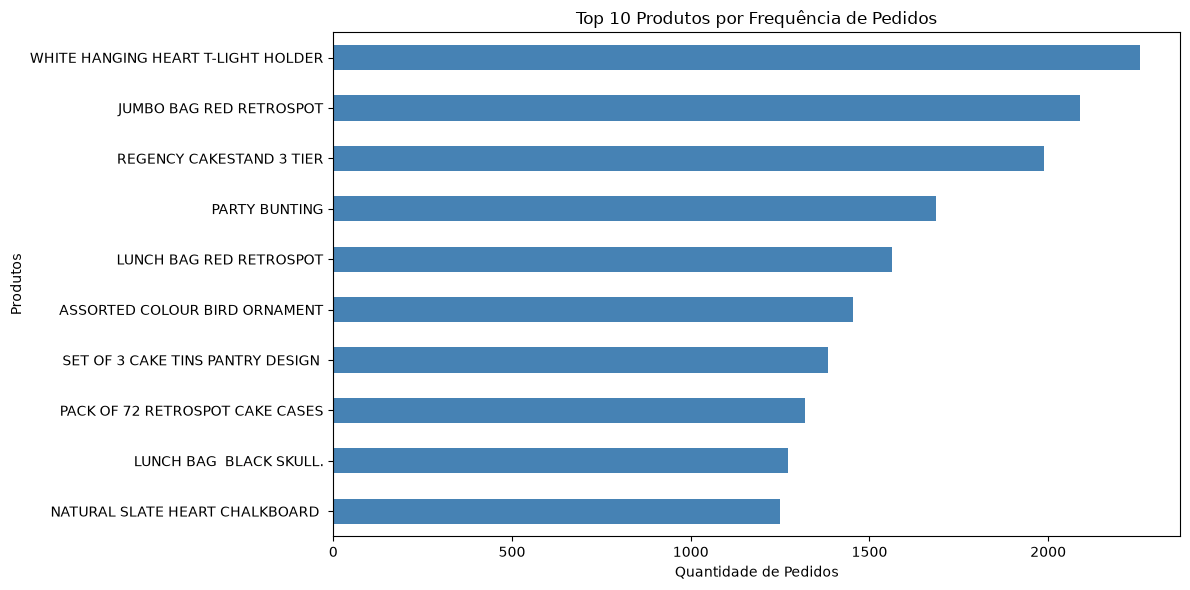

In [267]:
plt.figure(figsize=(12, 6))

produtos_mais_pedidos.sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 10 Produtos por Frequência de Pedidos")
plt.xlabel("Quantidade de Pedidos")
plt.ylabel("Produtos")

plt.tight_layout()
plt.show()

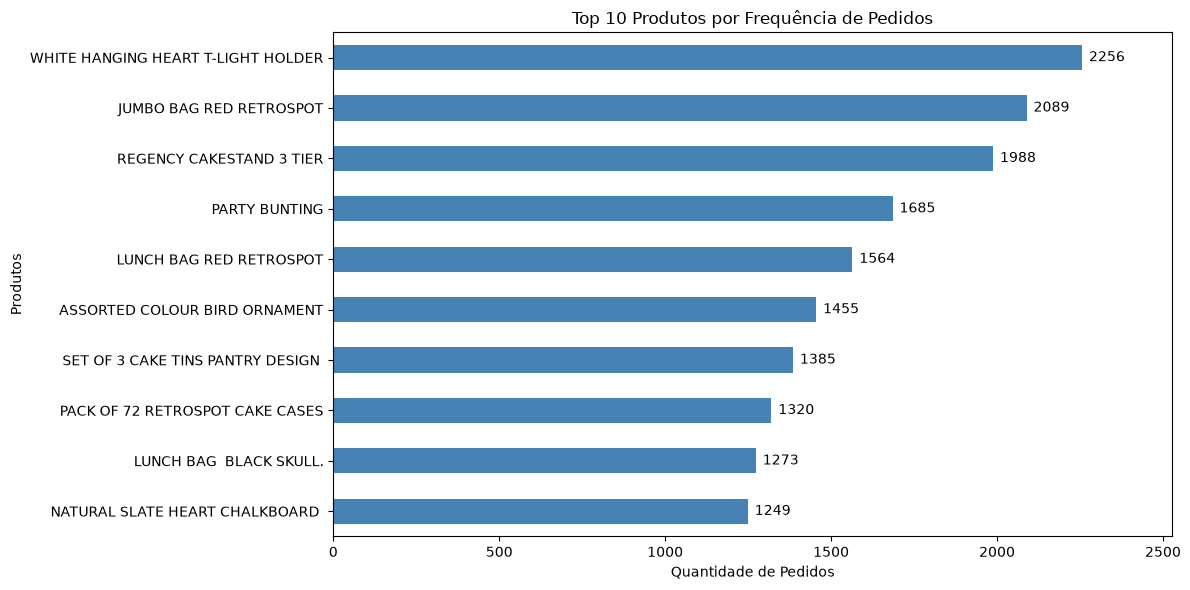

In [268]:
fig, ax = plt.subplots(figsize=(12, 6))

produtos_mais_pedidos.sort_values().plot(
    kind="barh",
    color="steelblue",
    ax=ax
)

ax.set_title("Top 10 Produtos por Frequência de Pedidos")
ax.set_xlabel("Quantidade de Pedidos")
ax.set_ylabel("Produtos")

ax.bar_label(ax.containers[0], padding=5)
ax.set_xlim(0, produtos_mais_pedidos.max() * 1.12)

plt.tight_layout()
plt.savefig("../graficos/top_10_produtos_pedidos.png", dpi=300, bbox_inches="tight")
plt.show()

In [269]:
faturamento_por_pais = (
    df_vendas.groupby("Country")["ValorTotal"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

faturamento_por_pais

Country
United Kingdom    9025222.084
Netherlands        285446.340
EIRE               283453.960
Germany            228867.140
France             209715.110
Australia          138521.310
Spain               61577.110
Switzerland         57089.900
Belgium             41196.340
Sweden              38378.330
Name: ValorTotal, dtype: float64

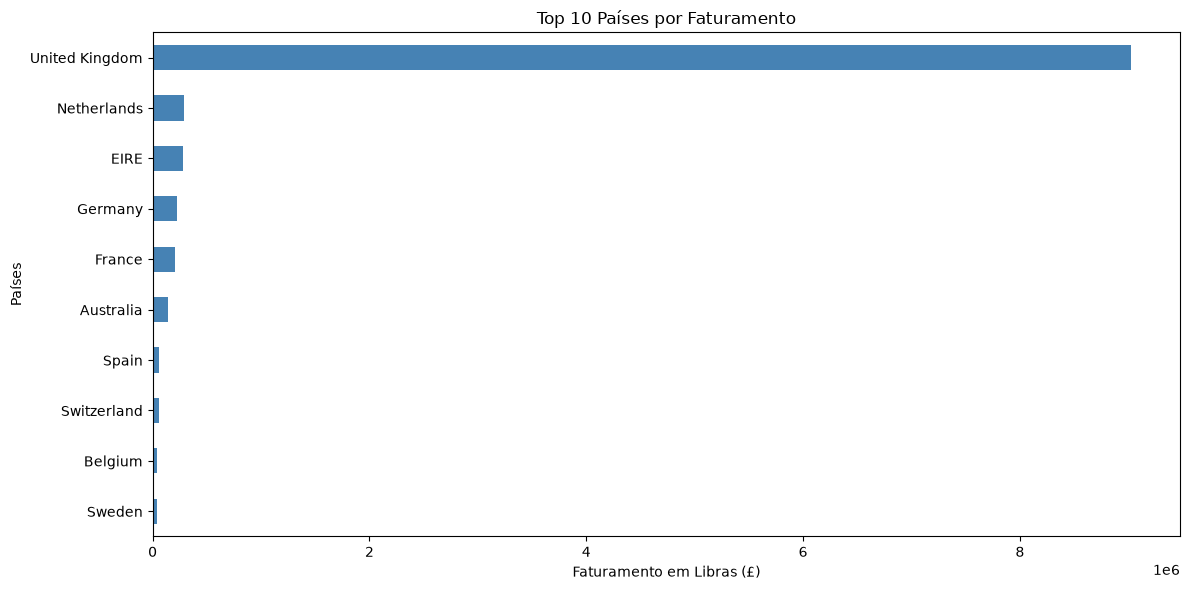

In [270]:
fig, ax = plt.subplots(figsize=(12, 6))

faturamento_por_pais.sort_values().plot(
    kind="barh",
    color="steelblue",
    ax=ax
)

ax.set_title("Top 10 Países por Faturamento")
ax.set_xlabel("Faturamento em Libras (£)")
ax.set_ylabel("Países")

plt.tight_layout()
plt.show()

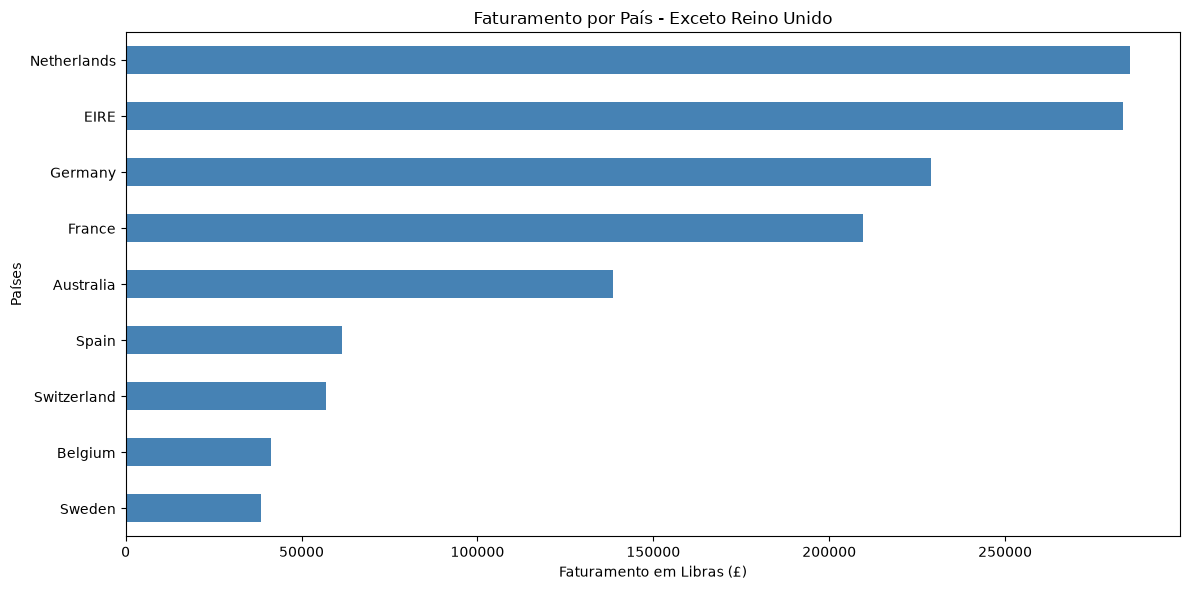

In [271]:
faturamento_internacional = faturamento_por_pais.drop("United Kingdom")

fig, ax = plt.subplots(figsize=(12, 6))

faturamento_internacional.sort_values().plot(
    kind="barh",
    color="steelblue",
    ax=ax
)

ax.set_title("Faturamento por País - Exceto Reino Unido")
ax.set_xlabel("Faturamento em Libras (£)")
ax.set_ylabel("Países")

plt.tight_layout()
plt.savefig("../graficos/faturamento_internacional.png", dpi=300, bbox_inches="tight")
plt.show()

In [272]:
df_vendas["AnoMes"] = df_vendas["InvoiceDate"].dt.to_period("M")

df_vendas[["InvoiceDate", "AnoMes"]].head(10)

,InvoiceDate,AnoMes
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12
5,2010-12-01 08:26:00,2010-12
6,2010-12-01 08:26:00,2010-12
7,2010-12-01 08:28:00,2010-12
8,2010-12-01 08:28:00,2010-12
9,2010-12-01 08:34:00,2010-12


In [273]:
faturamento_mensal = (
    df_vendas.groupby("AnoMes")["ValorTotal"]
    .sum()
    .sort_index()
)

faturamento_mensal

AnoMes
2010-12     823746.140
2011-01     691364.560
2011-02     523631.890
2011-03     717639.360
2011-04     537808.621
2011-05     770536.020
2011-06     761739.900
2011-07     719221.191
2011-08     759138.380
2011-09    1058590.172
2011-10    1154979.300
2011-11    1509496.330
2011-12     638792.680
Freq: M, Name: ValorTotal, dtype: float64

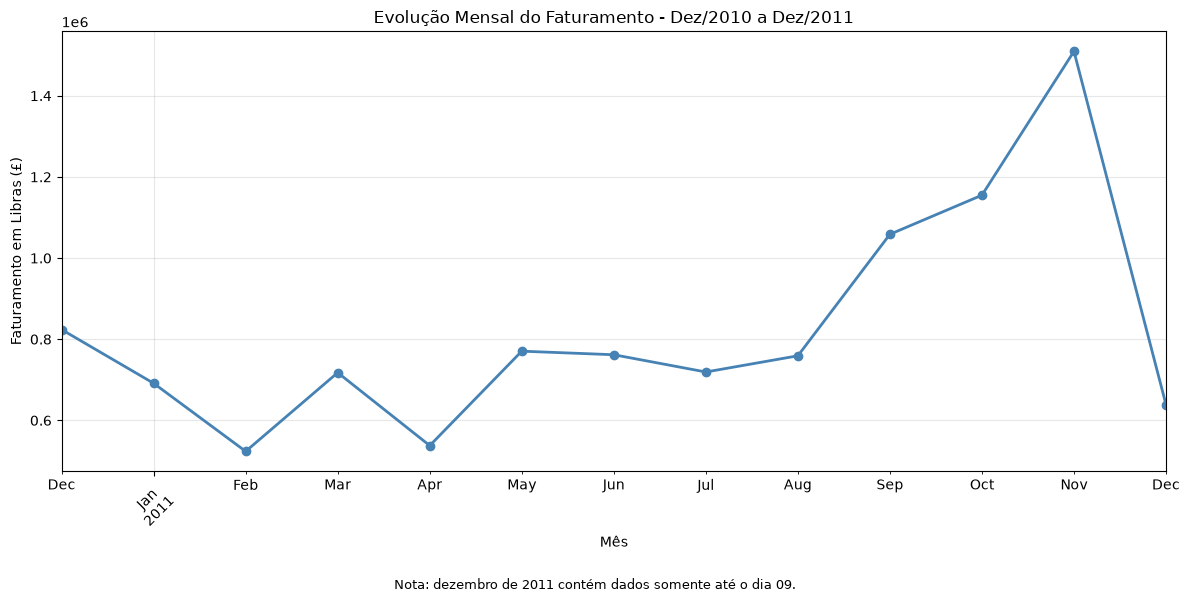

In [263]:
fig, ax = plt.subplots(figsize=(12, 6))

faturamento_mensal.plot(
    kind="line",
    marker="o",
    color="steelblue",
    linewidth=2,
    ax=ax
)

ax.set_title("Evolução Mensal do Faturamento - 2010 a 2011")
ax.set_xlabel("Mês")
ax.set_ylabel("Faturamento em Libras (£)")

ax.grid(True, alpha=0.3)

plt.xticks(rotation=45)
ax.set_title("Evolução Mensal do Faturamento - Dez/2010 a Dez/2011")

fig.text(
    0.5, 0.01,
    "Nota: dezembro de 2011 contém dados somente até o dia 09.",
    ha="center",
    fontsize=9
)
plt.tight_layout(rect=[0, 0.05, 1, 1])

plt.savefig(
    "../graficos/evolucao_faturamento_mensal.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [264]:
pedidos_mensais = (
    df_vendas.groupby("AnoMes")["InvoiceNo"]
    .nunique()
    .sort_index()
)

pedidos_mensais

AnoMes
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1361
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: InvoiceNo, dtype: int64

In [265]:
ticket_medio_mensal = faturamento_mensal / pedidos_mensais

ticket_medio_mensal.round(2)

AnoMes
2010-12    528.38
2011-01    636.62
2011-02    476.03
2011-03    493.56
2011-04    431.63
2011-05    458.38
2011-06    496.89
2011-07    487.61
2011-08    557.78
2011-09    576.26
2011-10    566.17
2011-11    545.14
2011-12    779.97
Freq: M, dtype: float64

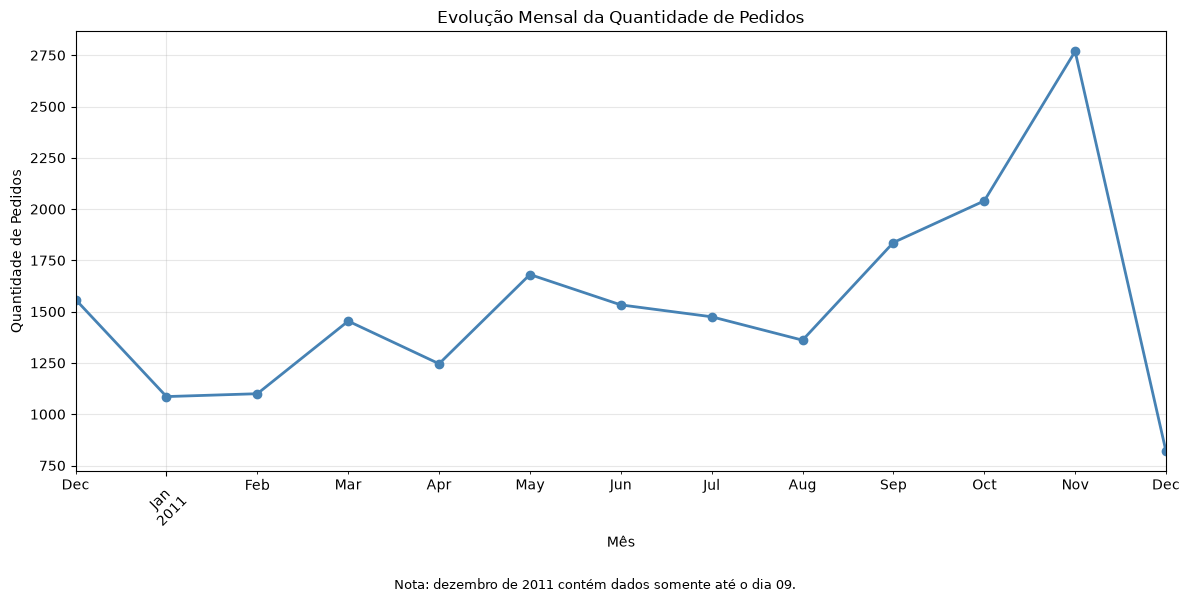

In [266]:
fig, ax = plt.subplots(figsize=(12, 6))

pedidos_mensais.plot(
    kind="line",
    marker="o",
    color="steelblue",
    linewidth=2,
    ax=ax
)

ax.set_title("Evolução Mensal da Quantidade de Pedidos")
ax.set_xlabel("Mês")
ax.set_ylabel("Quantidade de Pedidos")

ax.grid(True, alpha=0.3)

fig.text(
    0.5, 0.01,
    "Nota: dezembro de 2011 contém dados somente até o dia 09.",
    ha="center",
    fontsize=9
)

plt.xticks(rotation=45)
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.savefig(
    "../graficos/evolucao_pedidos_mensais.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [251]:
df_vendas.to_csv(
    "../data/processed/vendas_tratadas.csv",
    index=False,
    encoding="utf-8-sig"
)

In [4]:
df["UnitPrice"].value_counts().loc[
    lambda x: x.index <= 0
]

UnitPrice
 0.00        2515
-11062.06       2
Name: count, dtype: int64

In [3]:
df[df["UnitPrice"]< 0]

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


In [ ]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [ ]:
df.shape

(541909, 8)

In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


In [ ]:
df.isnull().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [ ]:
(df.isnull().sum() / len(df)* 100).round(2)

InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64

In [ ]:
df[["Quantity","UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


In [5]:
df["InvoiceNo"].astype(str).str.startswith("C").sum()

np.int64(9288)

In [8]:
(df["Quantity"] < 0).sum()

np.int64(10624)

In [3]:
df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].shape[0]

1336

In [4]:
df[
    (df["Quantity"] < 0) &
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
].head(10)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
2406,536589,21777,NaN,-10,2010-12-01 16:50:00,0.0,NaN,United Kingdom
4347,536764,84952C,NaN,-38,2010-12-02 14:42:00,0.0,NaN,United Kingdom
7188,536996,22712,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7189,536997,22028,NaN,-20,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7190,536998,85067,NaN,-6,2010-12-03 15:30:00,0.0,NaN,United Kingdom
7192,537000,21414,NaN,-22,2010-12-03 15:32:00,0.0,NaN,United Kingdom
7193,537001,21653,NaN,-6,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7195,537003,85126,NaN,-2,2010-12-03 15:33:00,0.0,NaN,United Kingdom
7196,537004,21814,NaN,-30,2010-12-03 15:34:00,0.0,NaN,United Kingdom
7197,537005,21692,NaN,-70,2010-12-03 15:35:00,0.0,NaN,United Kingdom


In [5]:
df[
    (df["Quantity"] < 0)&
    (~df["InvoiceNo"].astype(str).str.startswith("C"))
]["UnitPrice"].value_counts()

UnitPrice
0.0    1336
Name: count, dtype: int64

In [6]:
(df["UnitPrice"] <= 0).sum()

np.int64(2517)